# فصل اول — بازتولید مثال داده‌کاوی

این دفترچهٔ همراه فصل اول است. همهٔ داده‌ها **ساختگی** و در `transactions.csv` موجودند. ابتدا معیارهای قواعد انجمنی روی ده تراکنش محاسبه می‌شوند؛ سپس مسئلهٔ کشفیات کاذب در یک شبیه‌سازی مستقل نشان داده می‌شود.

In [1]:
from chapter01_example import load_baskets, count, rule
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

baskets = load_baskets()
assert len(baskets) == 10
print('تعداد تراکنش‌ها:', len(baskets))
for i, basket in enumerate(baskets, 1):
    print(i, '، '.join(sorted(basket)))

تعداد تراکنش‌ها: 10
1 شیر، نان، پوشک
2 شیر، نان
3 تخم‌مرغ، شیر، پوشک
4 شیر، نان، پوشک، کره
5 نان، چای
6 آبمیوه، پوشک
7 شیر، نان، پوشک
8 نان، کره
9 شیر، پوشک، چای
10 تخم‌مرغ، شیر، نان، پوشک


## محاسبهٔ دستی و عددی

برای قاعدهٔ پوشک $\Rightarrow$ شیر، تعداد پوشک ۷، تعداد شیر ۷ و تعداد مشترک ۶ است. بنابراین Support برابر ۰٫۶، Confidence برابر $6/7$، Lift برابر $60/49$ و Leverage برابر ۰٫۱۱ می‌شود.

In [2]:
results = pd.DataFrame([
    {'قاعده': f'{a} => {b}', **rule(baskets, a, b)}
    for a, b in [('پوشک', 'شیر'), ('آبمیوه', 'پوشک'), ('نان', 'شیر')]
])
assert count(baskets, 'پوشک', 'شیر') == 6
assert np.isclose(results.loc[0, 'lift'], 60/49)
assert np.isclose(results.loc[0, 'leverage'], .11)
print(results[['قاعده', 'A', 'B', 'AB', 'support', 'confidence', 'lift', 'leverage']].to_string(index=False))

         قاعده  A  B  AB  support  confidence     lift  leverage
   پوشک => شیر  7  7   6      0.6    0.857143 1.224490      0.11
آبمیوه => پوشک  1  7   1      0.1    1.000000 1.428571      0.03
    نان => شیر  7  7   5      0.5    0.714286 1.020408      0.01


## مقایسهٔ Support و Confidence

قاعدة «آبمیوه $\Rightarrow$ پوشک» اطمینان ۱۰۰ درصد دارد ولی فقط از یک خرید پشتیبانی می‌شود. اختلاف حجم شواهد در نمودار آشکار می‌شود.

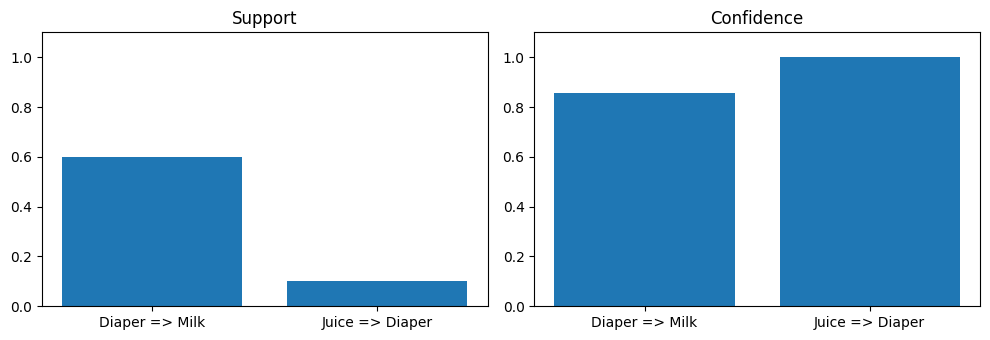

In [3]:
labels = ['Diaper => Milk', 'Juice => Diaper']
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar(labels, [0.6, 0.1]); ax[0].set(title='Support', ylim=(0, 1.1))
ax[1].bar(labels, [6/7, 1.0]); ax[1].set(title='Confidence', ylim=(0, 1.1))
plt.tight_layout()
plt.show()

## شبیه‌سازی مسئلهٔ چند آزمون

در این آزمایش آموزشی، ۵۰۰۰ بار ۱۰۰ مقدار $p$ مستقل یکنواخت تولید می‌کنیم و تعداد مقادیر کمتر از ۰٫۰۵ را می‌شماریم. این آزمایش **آزمون آماری واقعی دادهٔ فروشگاه نیست**؛ فقط شمار کشفیات کاذب را تحت فرض‌های شفاف نشان می‌دهد.

میانگین تجربی: 4.982
میانگین نظری: 5.0
احتمال نظری حداقل یک هشدار اشتباه: 0.994079


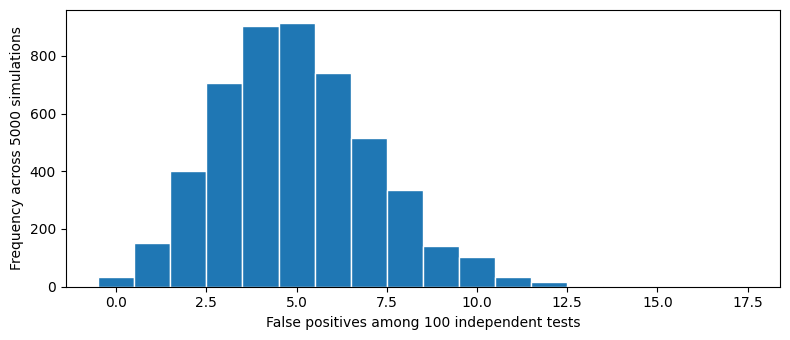

In [4]:
rng = np.random.default_rng(1234)
false_discoveries = (rng.uniform(size=(5000, 100)) < 0.05).sum(axis=1)
print('میانگین تجربی:', round(float(false_discoveries.mean()), 3))
print('میانگین نظری:', 100 * 0.05)
print('احتمال نظری حداقل یک هشدار اشتباه:', round(1-.95**100, 6))
assert abs(false_discoveries.mean() - 5) < 0.35
plt.figure(figsize=(8, 3.5))
plt.hist(false_discoveries, bins=np.arange(-0.5, 18.5, 1), edgecolor='white')
plt.xlabel('False positives among 100 independent tests')
plt.ylabel('Frequency across 5000 simulations')
plt.tight_layout()
plt.show()